[![Mở trong Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/thanhmk/hocmaytrongtaichinh/blob/main/Module_4/L2.ipynb)

## HỌC MÁY TRONG TÀI CHÍNH
MODULE 4 | BÀI 2


---

# **HỌC TẬP KẾT HỢP TRONG THỰC TẾ**

|  |  |
|:---|:---|
|**Thời gian đọc** |  15 phút |
|**Kiến thức nền** | Bagging, Stacking, SVM, cây quyết định, Naïve Bayes, hồi quy logistic, đường cong ROC, AUC.  |
|**Từ khóa** |Bộ học cơ sở, mô hình Meta.  |


---

In [ ]:
# Chuẩn bị môi trường trên Colab (chạy ô này một lần trước khi chạy các ô khác)
import os, urllib.request, urllib.parse

BASE = "https://raw.githubusercontent.com/thanhmk/hocmaytrongtaichinh/main/Module_4/"
FILES = ['data_l2.csv']
for f in FILES:
    if not os.path.exists(f):
        urllib.request.urlretrieve(BASE + urllib.parse.quote(f), f)
        print("Đã tải:", f)

*Ở bài trước, ta đã giới thiệu hai phương pháp học tập kết hợp là bagging và stacking. Bài này áp dụng hai phương pháp đó bằng Python.*

## **1. Giới thiệu**

Trong bài toán dự báo này, ta áp dụng các phương pháp kết hợp để dự báo chỉ số Luxembourg (LUXXX) có vượt mức lợi suất 0,25% theo bất kỳ hướng nào hay không. Các biến dự báo là sự kết hợp giữa các chỉ số quốc gia và các chỉ báo kỹ thuật. Ta bắt đầu bằng việc nạp dữ liệu.

In [1]:
import warnings

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")


data_df = pd.read_csv("data_l2.csv")
# Convert string to datetime
data_df["Date"] = pd.to_datetime(data_df["Date"])

Ta tạo biến mục tiêu như trước.

In [2]:
# Set Target Index for predicting
target_ETF = "LUXXX"

# Use returns instead of prices for other Indices
# Other Indices used as Index_features
ETF_features = data_df.loc[:, ~data_df.columns.isin(["Date", target_ETF])].columns
data_df[ETF_features] = data_df[ETF_features].pct_change()

data_df[target_ETF + "_returns"] = data_df[target_ETF].pct_change()

# Create Target Column.
# Shift period for target column
data_df[target_ETF + "_returns" + "_Shift"] = data_df[target_ETF + "_returns"].shift(-1)

# Strategy to take long position for anticipated returns of 0.5%
data_df["Target"] = np.where(
    (data_df[target_ETF + "_returns_Shift"].abs() > 0.025), 1, 0
)

Tạo các biến dự báo bên dưới, gồm bốn chỉ số quốc gia và ba chỉ báo kỹ thuật: tỷ số đường trung bình động chậm trên nhanh (SMA_ratio), chỉ số sức mạnh tương đối (RSI) và tốc độ thay đổi (RC).

In [3]:
# Four country indices used.
feats = ["MSCI KOREA", "MSCI DENMARK", "MSCI FRANCE", "MSCI NORWAY"]

# creating the technical indicators
data_df["SMA_5"] = data_df[target_ETF].rolling(5).mean()
data_df["SMA_15"] = data_df[target_ETF].rolling(15).mean()
data_df["SMA_ratio"] = data_df["SMA_15"] / data_df["SMA_5"]

# Can drop SMA columns since not needed anymore.
data_df.drop(["SMA_5", "SMA_15"], axis=1, inplace=True)


# shift the price of the target by 1 unit previous in time
data_df["Diff"] = data_df[target_ETF] - data_df[target_ETF].shift(1)
data_df["Up"] = data_df["Diff"]
data_df.loc[(data_df["Up"] < 0), "Up"] = 0

data_df["Down"] = data_df["Diff"]
data_df.loc[(data_df["Down"] > 0), "Down"] = 0
data_df["Down"] = abs(data_df["Down"])

data_df["avg_5up"] = data_df["Up"].rolling(5).mean()
data_df["avg_5down"] = data_df["Down"].rolling(5).mean()

data_df["avg_15up"] = data_df["Up"].rolling(15).mean()
data_df["avg_15down"] = data_df["Down"].rolling(15).mean()

data_df["RS_5"] = data_df["avg_5up"] / data_df["avg_5down"]
data_df["RS_15"] = data_df["avg_15up"] / data_df["avg_15down"]

data_df["RSI_5"] = 100 - (100 / (1 + data_df["RS_5"]))
data_df["RSI_15"] = 100 - (100 / (1 + data_df["RS_15"]))

data_df["RSI_ratio"] = data_df["RSI_5"] / data_df["RSI_15"]

# Can drop RS Calc columns columns
data_df.drop(
    ["Diff", "Up", "Down", "avg_5up", "avg_5down", "avg_15up", "avg_15down"],
    axis=1,
    inplace=True,
)

data_df["RC"] = data_df[target_ETF].pct_change(periods=15)

# all_feats
feats.append("SMA_ratio")
feats.append("RSI_ratio")
feats.append("RC")

Bây giờ đã có dữ liệu, ta có thể áp dụng các phương pháp kết hợp, bắt đầu từ bagging.

## **2. Bagging với rừng ngẫu nhiên**

Một ví dụ về bộ phân loại dùng thuật toán bagging là bộ phân loại rừng ngẫu nhiên (random forest). Rừng ngẫu nhiên là thuật toán dựa trên cây, do đó các bộ học yếu là cây quyết định. Chữ "ngẫu nhiên" chủ yếu nói về các đặc trưng được gán ngẫu nhiên cho mỗi cây quyết định; vì vậy các bộ học yếu không dùng mọi đặc trưng. Các tập con đặc trưng khác nhau và các mẫu khác nhau mà cây quyết định dùng cũng làm các cây không tương quan với nhau, nhờ đó cải thiện hiệu suất thuật toán. Kết quả cuối cùng đơn giản là bỏ phiếu đa số giữa các bộ học yếu. Chẳng hạn nếu rừng ngẫu nhiên có năm cây quyết định, trong đó ba cây dự báo nhóm 1 và hai cây dự báo nhóm 0, thì rừng ngẫu nhiên phân loại là nhóm 1 do dự báo đa số. Ta bắt đầu bằng việc nạp các thư viện cần thiết.

In [4]:
from sklearn import model_selection
from sklearn.ensemble import RandomForestClassifier

Thực hiện chia huấn luyện/kiểm tra theo tỷ lệ 80/20.

In [5]:
# Train/Test split
# Train/Test split. No NaNs in the data.
NoNaN_df = data_df.dropna()
X = NoNaN_df[feats]

X = X.iloc[:, :]  # .values
y = NoNaN_df.loc[:, "Target"]  # .values

del NoNaN_df

# from sklearn.cross_validation import train_test_split
X_train, X_test, y_train, y_test = model_selection.train_test_split(
    X, y, test_size=0.2, random_state=0
)

Bây giờ ta tạo bộ phân loại rừng ngẫu nhiên. Ta gọi nó là mô hình bag vì đây là bộ phân loại bagging. Trong các siêu tham số được chỉ định có n_estimators, là số cây. Để giảm thời gian huấn luyện, ta dùng số cây nhỏ là 10. Theo James (341), số cây lớn sẽ không gây quá khớp.

In [6]:
bagmodel = RandomForestClassifier(n_estimators=10, random_state=4)

Ta huấn luyện mô hình và xem độ chính xác trên tập huấn luyện và tập kiểm tra.

In [7]:
bagmodel.fit(X_train, y_train)

print("Accuracy on train set: %0.4f" % (bagmodel.score(X_train, y_train)))
print("Accuracy on test set: %0.4f" % (bagmodel.score(X_test, y_test)))

Accuracy on train set: 0.9787
Accuracy on test set: 0.5208


Chênh lệch lớn giữa độ chính xác trên tập huấn luyện và tập kiểm tra cho thấy quá khớp. Ta sẽ tìm giá trị siêu tham số tối ưu để cải thiện hiệu suất, chẳng hạn *min_samples_split*, là số mẫu tối thiểu cần có để chia một nút trong. Ta đã nhắc đến *max_depth* ở Bài 3 của Module 3 cho cây quyết định, và nó cũng như vậy với rừng ngẫu nhiên. Do sức tính toán hạn chế và cần thời gian xử lý nhanh, ta chỉ thử một vài giá trị mẫu cho các tham số này. Ta dùng `GridSearchCV` như ở Bài 2 của Module 5 để tìm siêu tham số tối ưu.

In [8]:
from sklearn.model_selection import GridSearchCV

In [9]:
# defining parameter range
param_grid = {
    "n_estimators": [10],
    "max_depth": [2, 3, 4],
    "min_samples_split": [2, 4, 8],
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=8), param_grid, refit=True, verbose=3, cv=3
)

# fitting the model for grid search
grid.fit(X_train, y_train)

Fitting 3 folds for each of 9 candidates, totalling 27 fits
[CV 1/3] END max_depth=2, min_samples_split=2, n_estimators=10;, score=0.698 total time=   0.0s
[CV 2/3] END max_depth=2, min_samples_split=2, n_estimators=10;, score=0.651 total time=   0.0s
[CV 3/3] END max_depth=2, min_samples_split=2, n_estimators=10;, score=0.661 total time=   0.0s
[CV 1/3] END max_depth=2, min_samples_split=4, n_estimators=10;, score=0.698 total time=   0.0s
[CV 2/3] END max_depth=2, min_samples_split=4, n_estimators=10;, score=0.651 total time=   0.0s
[CV 3/3] END max_depth=2, min_samples_split=4, n_estimators=10;, score=0.661 total time=   0.0s
[CV 1/3] END max_depth=2, min_samples_split=8, n_estimators=10;, score=0.698 total time=   0.0s
[CV 2/3] END max_depth=2, min_samples_split=8, n_estimators=10;, score=0.635 total time=   0.0s
[CV 3/3] END max_depth=2, min_samples_split=8, n_estimators=10;, score=0.694 total time=   0.0s
[CV 1/3] END max_depth=3, min_samples_split=2, n_estimators=10;, score=0.683

,estimator,RandomForestC...andom_state=8)
,param_grid,"{'max_depth': [2, 3, ...], 'min_samples_split': [2, 4, ...], 'n_estimators': [10]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,3
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,10


In [10]:
# print best parameter after tuning
print(grid.best_params_)

# print how our model looks after hyper-parameter tuning
print(grid.best_estimator_)

{'max_depth': 4, 'min_samples_split': 2, 'n_estimators': 10}
RandomForestClassifier(max_depth=4, n_estimators=10, random_state=8)


Áp dụng các tham số tối ưu và kiểm tra xem điểm trên tập kiểm tra có cải thiện không.

In [11]:
# Train with Tuned RF
# Create a tuned RF Classifier
bagmodel_tuned = RandomForestClassifier(
    n_estimators=10,
    max_depth=grid.best_params_["max_depth"],
    min_samples_split=grid.best_params_["min_samples_split"],
    random_state=8,
)

bagmodel_tuned.fit(X_train, y_train)
print("Accuracy on test set: %0.4f" % (bagmodel_tuned.score(X_test, y_test)))

Accuracy on test set: 0.5833


Độ chính xác trên tập kiểm tra tăng lên chỉ nhờ khám phá một không gian siêu tham số nhỏ. Ta dùng không gian siêu tham số nhỏ để giữ thời gian tính toán ở mức hợp lý. Bạn nên thử nhiều lựa chọn siêu tham số hơn. Một thước đo hiệu suất mô hình khác nên khám phá là sai số ngoài túi (out-of-bag), về cơ bản là sai số kiểm tra của mô hình bagging (James 342). Cần nhớ rằng độ chính xác dựa trên các nhóm dự báo, còn ROC AUC dựa trên điểm số dự báo. Vì vậy ta vẽ đường cong ROC như ở các module trước để so sánh với đoán ngẫu nhiên hay mô hình không có kỹ năng. Từ kết quả bên dưới, mô hình rừng ngẫu nhiên rõ ràng có lợi hơn mô hình không có kỹ năng.

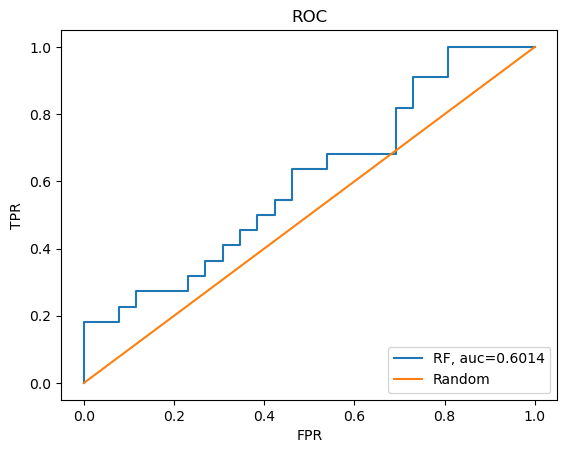

In [12]:
import matplotlib.pyplot as plt

# Performance
from sklearn.metrics import roc_auc_score, roc_curve

# predicted probabilities generated by tuned classifier
y_pred_proba = bagmodel_tuned.predict_proba(X_test)

# RF ROC dependencies
fpr, tpr, _ = roc_curve(y_test, y_pred_proba[:, 1])
auc = round(roc_auc_score(y_test, y_pred_proba[:, 1]), 4)

# RF Model
plt.plot(fpr, tpr, label="RF, auc=" + str(auc))

# Random guess model
plt.plot(fpr, fpr, "-", label="Random")
plt.title("ROC")
plt.ylabel("TPR")
plt.xlabel("FPR")

plt.legend(loc=4)
plt.show()

Một tính năng hữu ích khác của bagging là *điểm Out of Bag*: các quan sát không được lấy vào mẫu bootstrap của một cây có thể dùng để ước lượng sai số kiểm tra của mô hình bagging (James 342).

## **3. Mô hình stacking**

Mô hình stacking phụ thuộc vào các mô hình cơ sở và mô hình meta. Trong minh họa này, ta dùng các bộ phân loại Gaussian Naïve Bayes, cây quyết định và SVM làm mô hình cơ sở. Với mô hình meta, ta dùng mô hình hồi quy logistic đơn giản. Mục đích là để cho thấy ta có thể tận dụng mô hình hồi quy logistic bằng stacking như thế nào. Ta nạp các thư viện cần thiết cho từng mô hình. Tên gọi được mô tả rõ nên dễ khớp với từng mô hình.

In [14]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

Ta định nghĩa ba bộ phân loại cơ sở không chỉ định siêu tham số nào, tức là dùng thiết lập mặc định, ngoại trừ nhân (kernel) của SVC. Mục đích là cho thấy sức dự báo của stacking mà không cần tối ưu hóa.

In [15]:
clf1 = DecisionTreeClassifier(random_state=2)  # Decision Tree

clf2 = SVC(kernel="rbf", random_state=2)  # Support Vector Classifier

clf3 = GaussianNB()  # Gaussian Naive Bayes

est_rs = [("DTree", clf1), ("SVM", clf2), ("NB", clf3)]

Định nghĩa mô hình meta.

In [16]:
mylr = LogisticRegression(random_state=2)

In [17]:
# creating a stacking classifier
stackingCLF = StackingClassifier(
    estimators=est_rs, final_estimator=mylr, stack_method="auto", cv=3
)

Mô hình stacking đã sẵn sàng, và bây giờ ta cần huấn luyện nó trên dữ liệu huấn luyện. Ta cũng cho xem điểm huấn luyện vì muốn so sánh với từng bộ học cơ sở của nó ở bên dưới.

In [18]:
stackingCLF.fit(X_train, y_train)
acc_score = stackingCLF.score(X_train, y_train)
round(acc_score, 4)

0.7021

In [19]:
# Let's run the individual base learners and stacking `clf` to compare
for iterclf, iterlabel in zip([clf1, clf2, clf3], ["DTree", "SVM", "NB"]):
    scores = model_selection.cross_val_score(
        iterclf, X_train, y_train, cv=3, scoring="accuracy"
    )
    print("accuracy: %0.3f %s " % (scores.mean(), iterlabel))

accuracy: 0.559 DTree 
accuracy: 0.697 SVM 
accuracy: 0.686 NB 


Rõ ràng mô hình stacking vượt trội tất cả các bộ học cơ sở của nó, cho thấy lợi ích của học tập kết hợp trong trường hợp này. Nên so sánh hiệu suất của hai mô hình học tập kết hợp dùng trong bài; do đó ta xem đường cong ROC và AUC của mô hình stacking so với mô hình rừng ngẫu nhiên.

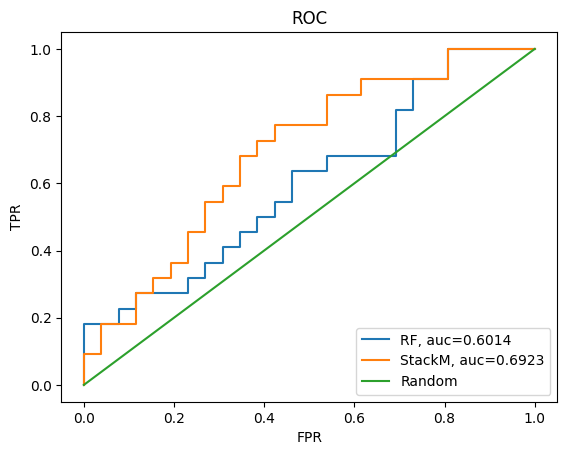

In [20]:
# predicted probabilities generated by tuned classifier
y_pred_probaStack = stackingCLF.predict_proba(X_test)

# Stacking Model ROC dependencies
fpr, tpr, _ = roc_curve(y_test, y_pred_probaStack[:, 1])
auc = round(roc_auc_score(y_test, y_pred_probaStack[:, 1]), 4)

# RF ROC dependencies
fpr_RF, tpr_RF, _ = roc_curve(y_test, y_pred_proba[:, 1])
auc_RF = round(roc_auc_score(y_test, y_pred_proba[:, 1]), 4)

# RF Model
plt.plot(fpr_RF, tpr_RF, label="RF, auc=" + str(auc_RF))
# Stacking Model
plt.plot(fpr, tpr, label="StackM, auc=" + str(auc))

# Random guess model
plt.plot(fpr, fpr, "-", label="Random")
plt.title("ROC")
plt.ylabel("TPR")
plt.xlabel("FPR")

plt.legend(loc=4)
plt.show()

Từ biểu đồ trên, rõ ràng mô hình stacking nhỉnh hơn một chút so với mô hình rừng ngẫu nhiên.

## **4. Kết luận**

Bài này xem bagging và stacking trong thực tế để dự báo sự thay đổi của chỉ số LUXXX vượt một ngưỡng nhất định, tức là một bài toán phân loại. Cả hai phương pháp đều cho thấy giá trị tăng thêm so với mô hình không có kỹ năng. Ở bài tiếp theo, ta sẽ nói về một phương pháp học tập kết hợp khác là boosting và boosting thích nghi.

**Tài liệu tham khảo**

James, Gareth et al. *An Introduction to Statistical Learning: With Applications in R.* 2nd ed., Springer, 2021.